# Ray Tracing -- Magnification

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch03/ch03-02.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** run the setup cell below first. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

In [ ]:
# --- Setup: run this cell first.  It does nothing outside Google Colab. ---
import sys, os, importlib.util, urllib.request
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # interactive matplotlib (%matplotlib widget) needs ipympl and Colab's custom widget manager
    if importlib.util.find_spec("ipympl") is None:
        get_ipython().run_line_magic("pip", "install -q ipympl")
        importlib.invalidate_caches()  # make the freshly installed package importable
        try:  # matplotlib caches its backend list on first use; refresh it so no restart is needed
            from matplotlib.backends.registry import backend_registry
            backend_registry._clear()
        except Exception:
            pass
    import ipympl  # noqa: F401
    from google.colab import output
    output.enable_custom_widget_manager()
    print("Colab setup done. If a %matplotlib widget cell still errors, use Runtime > Restart session, then Run all.")

## Import libraries

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

## Define parameters and plot

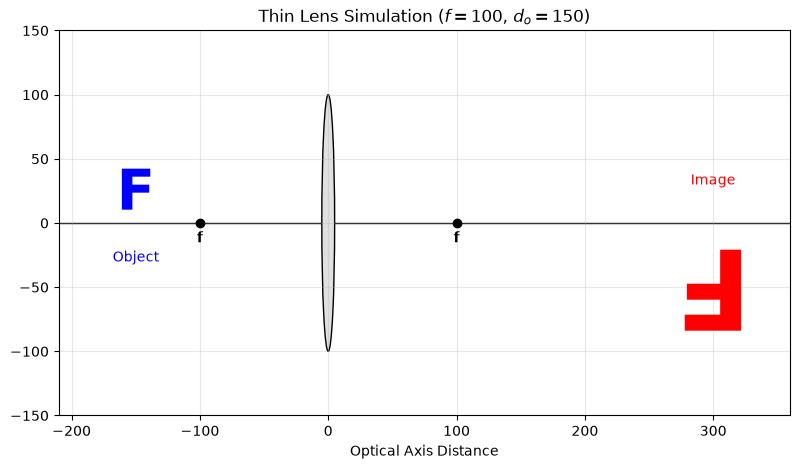

In [2]:
# --- Constants ---
LETTER = 'F'
OBJ_SIZE = 40  # Base font size
OBJ_COLOR = 'blue'
IMG_COLOR = 'red'

def draw_thin_lens_final(f, d_o):
    fig, ax = plt.subplots(figsize=(10, 5))
    
    # 1. Physics: Thin Lens Equation
    if abs(d_o - f) < 0.1:
        d_i, mag = np.inf, 0
    else:
        d_i = (f * d_o) / (d_o - f)
        mag = -d_i / d_o

    # 2. Draw Lens and Axis
    ax.axhline(0, color='black', lw=1, zorder=0)
    # Draw narrow oval lens
    lens = patches.Ellipse((0, 0), width=10, height=200, color='#e0e0e0', ec='black')
    ax.add_patch(lens)

    # 3. Draw Object
    # Placed at -d_o. Upright.
    ax.text(-d_o, 0, LETTER, fontsize=OBJ_SIZE, color=OBJ_COLOR,
            ha='center', va='bottom', fontweight='bold')
    ax.text(-d_o, -30, 'Object', ha='center', color=OBJ_COLOR)

    # 4. Draw Image
    if np.isinf(d_i):
        ax.text(f, 50, "Image at Infinity", ha='center')
    else:
        # Magnification affects size
        img_size = max(5, OBJ_SIZE * abs(mag))
        
        # Orientation Logic
        # Real Image (mag < 0): Rotated 180 degrees (Inverted + Mirrored)
        # Virtual Image (mag > 0): Rotated 0 degrees (Upright)
        rotation_angle = 180 if mag < 0 else 0
        
        # Draw the letter
        ax.text(d_i, 0, LETTER, fontsize=img_size, color=IMG_COLOR,
                ha='center', va='bottom', fontweight='bold',
                rotation=rotation_angle, rotation_mode='anchor')
        
        # Label (without magnification value)
        label_y = 30 if mag < 0 else -30
        ax.text(d_i, label_y, 'Image', ha='center', color=IMG_COLOR)

    # 5. Focal Points (Black circles + 'f')
    # Draw points at -f and +f
    ax.plot([-f, f], [0, 0], 'ko', ms=6, zorder=3) 
    # Label them
    ax.text(-f, -15, 'f', ha='center', color='black', fontweight='bold')
    ax.text(f, -15, 'f', ha='center', color='black', fontweight='bold')

    # 6. Styling
    # Set limits to comfortably fit object and image
    margin = 60
    view_min = min(-d_o, 0, d_i if not np.isinf(d_i) else 0) - margin
    view_max = max(0, d_o, d_i if not np.isinf(d_i) else 0) + margin
    
    ax.set_xlim(view_min, view_max)
    ax.set_ylim(-150, 150)
    ax.set_aspect('equal')
    ax.set_title(f'Thin Lens Simulation ($f={f}$, $d_o={d_o}$)')
    ax.set_xlabel('Optical Axis Distance')
    ax.grid(True, alpha=0.3)

    return fig

# Run with settings that produce a Real, Inverted Image
fig = draw_thin_lens_final(f=100, d_o=150)
plt.show()

## Make interactive with `matplotlib` and `ipywidgets`

In [3]:
%matplotlib widget
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import ipywidgets as widgets
import numpy as np

# --- Configuration ---
LETTER2 = 'F'
OBJ_SIZE2 = 40
OBJ_COLOR2 = 'blue'
IMG_COLOR2 = 'red'
FOCAL_LENGTH = 100

# 1. Create the Figure ONCE
plt.close('all') 
fig2, ax = plt.subplots(figsize=(9, 5))
plt.subplots_adjust(bottom=0.2)

# HIDE the "Figure 1" header bar
fig2.canvas.header_visible = False 
fig2.canvas.footer_visible = False # Optional: hides the bottom toolbar if you want cleaner look

# 2. Setup Static Elements
lens = patches.Ellipse((0, 0), width=10, height=200, color='#e0e0e0', ec='black')
ax.add_patch(lens)
ax.axhline(0, color='black', lw=1, zorder=0)

# Focal Points
ax.plot([-FOCAL_LENGTH, FOCAL_LENGTH], [0, 0], 'ko', ms=6, zorder=3)
ax.text(-FOCAL_LENGTH, -25, 'f', ha='center', color='black', fontweight='bold')
ax.text(FOCAL_LENGTH, -25, 'f', ha='center', color='black', fontweight='bold')

# 3. Setup Dynamic Elements
# Object
txt_obj = ax.text(-150, 0, LETTER2, fontsize=OBJ_SIZE2, color=OBJ_COLOR2,
                  ha='center', va='bottom', fontweight='bold')
lbl_obj = ax.text(-150, -40, 'Object', ha='center', color=OBJ_COLOR2)

# Image
txt_img = ax.text(300, 0, LETTER2, fontsize=OBJ_SIZE2, color=IMG_COLOR2,
                  ha='center', va='bottom', fontweight='bold')
lbl_img = ax.text(300, -40, 'Image', ha='center', color=IMG_COLOR2)

# Infinity Label (Hidden by default)
txt_inf = ax.text(FOCAL_LENGTH, 50, "Image at Infinity", ha='center', 
                  color=IMG_COLOR2, visible=False)

# Styling
ax.set_ylim(-150, 150)
ax.set_xlim(-400, 400)
ax.set_aspect('equal')
ax.set_title(f'Thin Lens ($f={FOCAL_LENGTH}$)')
ax.grid(True, alpha=0.3)

# 4. The Logic Function
def update_plot(d_o):
    """Calculates physics and updates existing artists."""
    f = FOCAL_LENGTH
    
    # Physics
    if abs(d_o - f) < 0.1:
        # Infinity case
        txt_img.set_visible(False)
        lbl_img.set_visible(False)
        txt_inf.set_visible(True)
    else:
        d_i = (f * d_o) / (d_o - f)
        mag = -d_i / d_o
        
        # Visibility
        txt_img.set_visible(True)
        lbl_img.set_visible(True)
        txt_inf.set_visible(False)
        
        # Update Object
        txt_obj.set_x(-d_o)
        lbl_obj.set_x(-d_o)
        
        # Update Image Position
        txt_img.set_x(d_i)
        lbl_img.set_x(d_i)
        
        # Update Image Size
        new_size = max(5, OBJ_SIZE2 * abs(mag))
        txt_img.set_fontsize(new_size)
        
        # Update Orientation (Rotation)
        # Real (mag < 0) = 180 deg, Virtual (mag > 0) = 0 deg
        rot = 180 if mag < 0 else 0
        txt_img.set_rotation(rot)
        
        # Update Label Position
        lbl_y = 40 if mag < 0 else -40
        lbl_img.set_y(lbl_y)
        
        # Update Title
        ax.set_title(f'Thin Lens ($f={FOCAL_LENGTH}$, $d_o={d_o:.0f}$)')

    fig2.canvas.draw_idle()

# 5. Connect Slider
slider = widgets.FloatSlider(value=150, min=50, max=350, step=2, description='Object Dist')
slider.observe(lambda change: update_plot(change['new']), names='value')

display(slider)

### Display animation with javascript from standalone html
[Link to animation](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch03/ch03-02_animation.html)

*Animation.* The pre-rendered animation for this section is shown on the [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch03/ch03-02.html) (direct link: [ch03-02_animation.html](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch03/ch03-02_animation.html)). It is not embedded here because Colab cannot load files from the textbook site; running the code above produces the live version.